In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [3]:
df = pd.read_csv("IrisData_full.csv", header=None)
df = df.sample(frac=1).reset_index(drop=True)
df.columns = ["Sepal_length", "Sepal_width", "Petal_length", "Petal_width", "Species"]

df.head()

,Sepal_length,Sepal_width,Petal_length,Petal_width,Species
0,4.8,3.0,1.4,0.3,Iris-setosa
1,6.7,3.1,5.6,2.4,Iris-virginica
2,5.5,2.4,3.7,1.0,Iris-versicolor
3,7.6,3.0,6.6,2.1,Iris-virginica
4,5.6,3.0,4.5,1.5,Iris-versicolor


In [4]:
x = df.iloc[:, :4].astype(float)
y = df.iloc[:, 4]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [5]:
def euclidian_distance(a, b):
    return np.sqrt(np.sum((b - a)**2))

In [6]:
class KNN:
    def __init__(self, k):
        self.k = k

    def fit(self, x, y):
        self.x_train = np.array(x)
        self.y_train = np.array(y)

    def predict(self, new_points):
        predictions = [self.predict_class(point) for point in new_points]
        return np.array(predictions)

    def predict_class(self, new_point):
        distances = [euclidian_distance(point, new_point) for point in self.x_train]

        k_nearest_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_nearest_indices]

        most_common = Counter(k_nearest_labels).most_common(1)[0][0]

        return most_common

In [13]:
knn = KNN(7)
knn.fit(x_train, y_train)
predictions = knn.predict(x_test)

accuracy = np.mean(predictions == np.array(y_test)) * 100
print("Accuracy:", accuracy)

Accuracy: 96.66666666666667


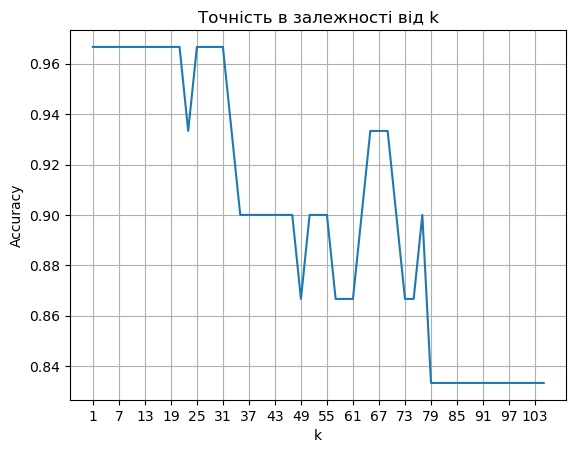

In [14]:
k_values = range(1, 107, 2)
accuracies = []

for k in k_values:
    knn = KNN(k)
    knn.fit(x_train, y_train)
    predictions = knn.predict(x_test)
    accuracy = np.mean(predictions == np.array(y_test))
    accuracies.append(accuracy)

plt.plot(k_values, accuracies)
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Точність в залежності від k")
plt.xticks(range(1, 107, 6))
plt.grid(True)
plt.show()

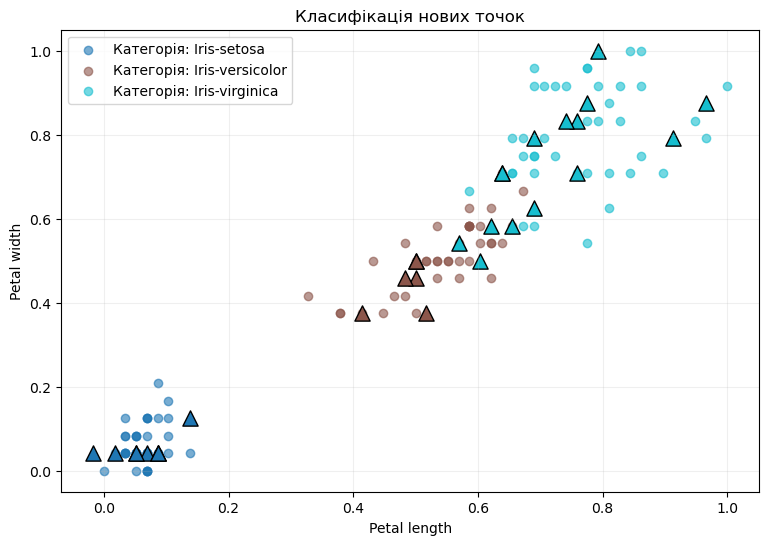

In [16]:
categories = np.unique(y_train)
colors = plt.cm.tab10(np.linspace(0, 1, len(categories)))
color_map = dict(zip(categories, colors))

plt.figure(figsize=(9, 6))

# Початкові точки навчальної вибірки
for category in categories:
    mask = np.array(y_train) == category
    plt.scatter(
        x_train[mask, 2], x_train[mask, 3],
        color=color_map[category],
        label=f"Категорія: {category}",
        alpha=0.6
    )

# Нові точки тестової вибірки: хрестики
for category in categories:
    mask = predictions == category
    plt.scatter(
        x_test[mask, 2], x_test[mask, 3],
        color=color_map[category],
        marker="^",
        edgecolors="black",
        s=120
    )

plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.title("Класифікація нових точок")
plt.legend()
plt.grid(alpha=0.2)
plt.show()